# Seven-Segment Meter Reading with COCO + YOLO — **v2 (extra-digit fix)**

**Problem in v1:** the true reading was `035260` but the notebook predicted `0355260` (one extra digit).

**Pipeline:** COCO JSON → YOLO dataset → train YOLO digit detector → detect digits → *clean the detections* → sort along the text line → meter reading.

### What changed compared with v1

| # | Change | Why it fixes / helps |
|---|--------|----------------------|
| 1 | `fliplr=0.0` (and `flipud=0.0`) during training | Horizontal flip turns a **2** into something that looks like a **5** (and vice-versa). v1 trained with the default `fliplr=0.5`, actively teaching the 2↔5 confusion. |
| 2 | Cross-class overlap suppression in the decoder | Two boxes on the *same* physical digit (e.g. a `5` and a `2`) are collapsed to the most confident one, so no extra digit appears. |
| 3 | Tilt-aware left-to-right ordering (PCA line fit) | Sorting by raw x can scramble digits in the *Tilted* images. |
| 4 | Confidence threshold tuned on the **validation** set | v1 used a fixed 0.25. |
| 5 | Ground-truth duplicate check | Duplicate/overlapping annotation boxes would teach the model to output duplicates. |
| 6 | Diagnosis cell | Shows *why* an image has an extra digit (duplicate vs. confusion). |
| 7 | **Exact-match accuracy** + error analysis | mAP is not reading accuracy; one wrong digit ruins the whole reading. |
| 8 | Auto config: bigger model / resolution on GPU | 7-segment digits are small and differ by only 1–2 segments. |

> **Tip:** switch to a GPU first (*Runtime → Change runtime type → T4 GPU*). v1 ran on CPU (about 1.3 h for 47 epochs).

## Module 0 — Install packages, helpers and runtime check

In [1]:
!pip -q install ultralytics opencv-python-headless pyyaml scikit-learn matplotlib

import os, json, random, shutil, re, math, zipfile, difflib
from pathlib import Path
from collections import defaultdict, Counter

import cv2
import yaml
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from ultralytics import YOLO
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

HAS_GPU = torch.cuda.is_available()
DEVICE = 0 if HAS_GPU else "cpu"
print("Torch:", torch.__version__)
print("CUDA available:", HAS_GPU)
if not HAS_GPU:
    print("WARNING: no GPU. Training will be slow and a small model is used. "
          "Use Runtime > Change runtime type > T4 GPU for best results.")

# ---------- geometry helpers (boxes are (x1, y1, x2, y2)) ----------
def _inter_and_areas(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    return inter, area_a, area_b

def iou_xyxy(a, b):
    inter, area_a, area_b = _inter_and_areas(a, b)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def overlap_min(a, b):
    # intersection divided by the SMALLER box: catches a small box sitting inside a big one
    inter, area_a, area_b = _inter_and_areas(a, b)
    m = min(area_a, area_b)
    return inter / m if m > 0 else 0.0

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Torch: 2.14.1+cu130
CUDA available: True


## Module 1 — Upload and extract the Mendeley dataset

Download the archive from [Mendeley Data](https://data.mendeley.com/datasets/fnn44p4mj8/1) and upload the ZIP. Nested ZIPs (e.g. `RAW IMAGES.zip`) are extracted automatically.

In [2]:
from google.colab import files
uploaded = files.upload()

zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
assert zip_files, "Upload the dataset ZIP file."

EXTRACT_ROOT = Path("/content/meter_dataset")
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

for z in zip_files:
    with zipfile.ZipFile(z, "r") as archive:
        archive.extractall(EXTRACT_ROOT)

# Recursively extract nested ZIPs
found_nested = True
while found_nested:
    found_nested = False
    for p in list(EXTRACT_ROOT.rglob("*.zip")):
        print("Extracting nested archive:", p.name)
        with zipfile.ZipFile(p, "r") as archive:
            archive.extractall(p.parent)
        p.unlink()           # delete after extraction to avoid an endless loop
        found_nested = True

print("Extracted to:", EXTRACT_ROOT)
for root, dirs, fnames in os.walk(EXTRACT_ROOT):
    if fnames:
        print(f"{Path(root).name} | files: {len(fnames)} | e.g. {fnames[:3]}")

Saving Data for Text detection and Recognition in Raw Image Dataset of Seven Segment Digital Energy Meter Display.zip to Data for Text detection and Recognition in Raw Image Dataset of Seven Segment Digital Energy Meter Display.zip
Extracting nested archive: RAW IMAGES.zip
Extracted to: /content/meter_dataset
Data for Text detection and Recognition in Raw Image Dataset of Seven Segment Digital Energy Meter Display | files: 1 | e.g. ['export-coco-2019-06-11T14_40_00.348423.json']
4)Blurred | files: 21 | e.g. ['150.JPG', '166.JPG', 'Thumbs.db']
3)Tilted | files: 51 | e.g. ['122.JPG', '126.JPG', '101.JPG']
1)Day Light | files: 51 | e.g. ['24.JPG', '47.JPG', 'Thumbs.db']
2)Night | files: 50 | e.g. ['91.JPG', '62.JPG', '82.JPG']


## Module 2 — Locate images and the COCO annotation JSON

In [3]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_paths = [p for p in EXTRACT_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
json_paths = [p for p in EXTRACT_ROOT.rglob("*.json") if p.is_file()]

print("Images found:", len(image_paths))
for i, p in enumerate(json_paths):
    print(i, p)

assert image_paths, "No images found. Check the extracted archive."
assert json_paths, "No COCO JSON found."

COCO_JSON = json_paths[0]   # change the index if several JSON files are listed
with open(COCO_JSON, "r", encoding="utf-8") as f:
    coco = json.load(f)

print("Using:", COCO_JSON.name)
print("Images in COCO:", len(coco.get("images", [])))
print("Annotations:", len(coco.get("annotations", [])))
print("Categories:", [c["name"] for c in coco.get("categories", [])])

Images found: 169
0 /content/meter_dataset/Data for Text detection and Recognition in Raw Image Dataset of Seven Segment Digital Energy Meter Display/export-coco-2019-06-11T14_40_00.348423.json
Using: export-coco-2019-06-11T14_40_00.348423.json
Images in COCO: 168
Annotations: 977
Categories: ['Text 1', 'Text 3', 'Text 4', 'Text 6', 'Text 0', 'Text 2', 'Text 8', 'Text 9', 'Text 7', 'Text 5']


## Module 3 — Map COCO categories to digit classes

In this dataset the categories are named `Text 0` … `Text 9` and the IDs are **not** in digit order, so the mapping matters. Fill `CUSTOM_CATEGORY_TO_DIGIT` only if your names differ.

In [4]:
categories = coco.get("categories", [])
cat_id_to_name = {int(c["id"]): str(c["name"]) for c in categories}

CUSTOM_CATEGORY_TO_DIGIT = {}   # optional manual override: {category_id: "digit"}

def infer_digit(category_name):
    name = str(category_name).strip().lower()
    if name in list("0123456789"):
        return name
    m = re.fullmatch(r"(?:text|digit|number|num)[ _-]*([0-9])", name)   # "Text 5", "digit_3", ...
    return m.group(1) if m else None

cat_id_to_digit = {}
for cid, name in cat_id_to_name.items():
    digit = CUSTOM_CATEGORY_TO_DIGIT.get(cid, infer_digit(name))
    if digit is not None:
        cat_id_to_digit[cid] = str(digit)

print("Digit category mapping:", dict(sorted(cat_id_to_digit.items(), key=lambda kv: kv[1])))
if set(cat_id_to_digit.values()) != set("0123456789"):
    print("\nWARNING: not all ten digit classes were found - fix CUSTOM_CATEGORY_TO_DIGIT.")

Digit category mapping: {5: '0', 1: '1', 6: '2', 2: '3', 3: '4', 10: '5', 4: '6', 9: '7', 7: '8', 8: '9'}


## Module 4 — Convert COCO boxes to YOLO labels (+ annotation sanity checks)

COCO box: `[x_left, y_top, w, h]` in **pixels**. YOLO label: `class x_center y_center w h`, **normalized to 0–1**.

New in v2: after conversion we check for **duplicate / heavily overlapping annotation boxes** (they teach the model to emit duplicate digits) and print the digit-count and class distributions.

In [5]:
assert cat_id_to_digit, "No digit categories mapped. Edit CUSTOM_CATEGORY_TO_DIGIT in Module 3."

DIGITS = list("0123456789")
digit_to_yolo = {d: i for i, d in enumerate(DIGITS)}
yolo_names = {i: d for d, i in digit_to_yolo.items()}

images_by_id = {str(im["id"]): im for im in coco["images"]}
anns_by_image = defaultdict(list)
for ann in coco.get("annotations", []):
    cid = int(ann.get("category_id", -1))
    if cid not in cat_id_to_digit or ann.get("iscrowd", 0):
        continue
    anns_by_image[str(ann["image_id"])].append(ann)

all_image_lookup = {}
for p in image_paths:
    all_image_lookup[p.name.lower()] = p
    all_image_lookup[str(p).replace("\\", "/").lower()] = p

def resolve_image(file_name):
    clean_name = str(file_name).replace("\\", "/").split("?")[0]
    base = Path(clean_name).name.lower()
    if base in all_image_lookup:
        return all_image_lookup[base]
    candidate = base.split("-")[-1]        # e.g. "...-113.jpg" -> "113.jpg"
    return all_image_lookup.get(candidate)

records, missing = [], []
for image_id, im in images_by_id.items():
    src = resolve_image(im.get("file_name", ""))
    if src is None:
        missing.append(im.get("file_name"))
        continue
    W, H = float(im.get("width", 0)), float(im.get("height", 0))
    if W <= 0 or H <= 0:
        arr = cv2.imread(str(src))
        if arr is None:
            continue
        H, W = arr.shape[:2]
    valid = []
    for ann in anns_by_image.get(image_id, []):
        x, y, w, h = map(float, ann.get("bbox", [0, 0, 0, 0]))
        if w <= 0 or h <= 0:
            continue
        x1, y1 = max(0, x), max(0, y)
        x2, y2 = min(W, x + w), min(H, y + h)
        if x2 <= x1 or y2 <= y1:
            continue
        digit = cat_id_to_digit[int(ann["category_id"])]
        valid.append((digit_to_yolo[digit], ((x1 + x2) / 2) / W, ((y1 + y2) / 2) / H,
                      (x2 - x1) / W, (y2 - y1) / H))
    if valid:
        records.append({"image_id": image_id, "src": src, "labels": valid})

print("Images with at least one digit box:", len(records))
print("Images with unresolved paths:", len(missing))
assert records, "No usable digit boxes."

# ---------- sanity check 1: duplicate / overlapping ground-truth boxes ----------
def lab_to_xyxy(l):
    _, xc, yc, w, h = l
    return (xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2)

DUP_IOU = 0.85          # boxes this similar are treated as duplicates and removed
n_removed, suspicious = 0, []
for rec in records:
    kept = []
    for lab in rec["labels"]:
        box = lab_to_xyxy(lab)
        if any(iou_xyxy(box, k[1]) > DUP_IOU for k in kept):
            n_removed += 1
            continue
        kept.append((lab, box))
    rec["labels"] = [k[0] for k in kept]
    for i in range(len(kept)):
        for j in range(i + 1, len(kept)):
            o = iou_xyxy(kept[i][1], kept[j][1])
            if o > 0.3:
                suspicious.append((rec["src"].name, DIGITS[kept[i][0][0]], DIGITS[kept[j][0][0]], round(o, 2)))

print(f"\nDuplicate GT boxes removed (IoU > {DUP_IOU}):", n_removed)
print("Images with overlapping GT boxes (IoU > 0.3) - inspect these manually:", len(suspicious))
for s in suspicious[:15]:
    print("  ", s)

# ---------- sanity check 2: distributions ----------
count_dist = Counter(len(r["labels"]) for r in records)
class_dist = Counter(DIGITS[l[0]] for r in records for l in r["labels"])
print("\nDigits per image (digits: images):", dict(sorted(count_dist.items())))
print("Instances per digit class:", dict(sorted(class_dist.items())))
print("Note: digits-per-image is NOT constant, so do not force a fixed digit count unless every meter has the same length.")

Images with at least one digit box: 168
Images with unresolved paths: 0

Duplicate GT boxes removed (IoU > 0.85): 0
Images with overlapping GT boxes (IoU > 0.3) - inspect these manually: 0

Digits per image (digits: images): {4: 10, 5: 74, 6: 28, 7: 49, 8: 7}
Instances per digit class: {'0': 241, '1': 106, '2': 102, '3': 112, '4': 83, '5': 70, '6': 52, '7': 68, '8': 62, '9': 81}
Note: digits-per-image is NOT constant, so do not force a fixed digit count unless every meter has the same length.


## Module 5 — Create train / validation / test folders

70 / 15 / 15 split. Validation is used for model selection **and for tuning the confidence threshold**; the test set is touched only for the final report.

> The split is random by image. If the same meter appears in several photos, near-duplicates can leak between splits and inflate results. Group by meter / session if you have that information.

In [6]:
DATASET_DIR = Path("/content/yolo_meter_digits")
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
for split in ["train", "val", "test"]:
    (DATASET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

indices = list(range(len(records)))
train_idx, temp_idx = train_test_split(indices, test_size=0.30, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED)

def write_split(idxs, split):
    for idx in idxs:
        rec = records[idx]
        src = rec["src"]
        out_name = f"img_{rec['image_id']}_{src.stem}{src.suffix.lower()}"
        shutil.copy2(src, DATASET_DIR / "images" / split / out_name)
        with open(DATASET_DIR / "labels" / split / (Path(out_name).stem + ".txt"), "w") as f:
            for cls, xc, yc, w, h in rec["labels"]:
                f.write(f"{cls} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")

write_split(train_idx, "train")
write_split(val_idx, "val")
write_split(test_idx, "test")

data_yaml = {"path": str(DATASET_DIR), "train": "images/train", "val": "images/val",
             "test": "images/test", "names": yolo_names}
yaml_path = DATASET_DIR / "meter_digits.yaml"
with open(yaml_path, "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print("Train / val / test:", len(train_idx), len(val_idx), len(test_idx))

Train / val / test: 117 25 26


## Module 6 — Visualize converted YOLO labels (sanity check)

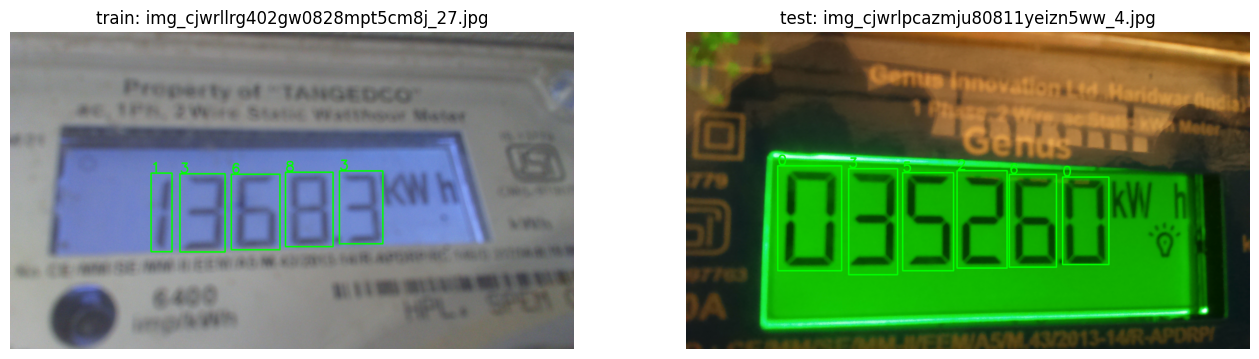

In [7]:
def show_yolo_sample(split="train", index=0, ax=None):
    p = sorted((DATASET_DIR / "images" / split).glob("*"))[index]
    img = cv2.imread(str(p))
    H, W = img.shape[:2]
    t = max(2, int(round(min(H, W) / 300)))
    fs = max(0.7, min(H, W) / 700)
    for line in (DATASET_DIR / "labels" / split / (p.stem + ".txt")).read_text().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())
        x1, y1 = int((xc - bw / 2) * W), int((yc - bh / 2) * H)
        x2, y2 = int((xc + bw / 2) * W), int((yc + bh / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), t)
        cv2.putText(img, DIGITS[int(cls)], (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, fs, (0, 255, 0), t)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{split}: {p.name}")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
show_yolo_sample("train", 0, axes[0])
show_yolo_sample("test", 0, axes[1])
plt.show()

## Module 7 — Train YOLO (improved settings)

Key changes vs v1:

* **`fliplr=0.0`, `flipud=0.0`** - never mirror digits. A mirrored `2` looks like a `5`.
* **`degrees=5`** - a little rotation augmentation, which matches the *Tilted* images without destroying digit identity.
* **Auto config:** on a GPU use `yolo11s` at 960 px, 150 epochs, patience 50. On CPU fall back to `yolo11n` at 640 px.
* **`close_mosaic=15`** - the last epochs train on un-mosaiced images, which are closer to inference conditions.

In [8]:
if HAS_GPU:
    MODEL_WEIGHTS, IMAGE_SIZE, EPOCHS, BATCH_SIZE, PATIENCE = "yolo11s.pt", 960, 150, 8, 50
else:
    MODEL_WEIGHTS, IMAGE_SIZE, EPOCHS, BATCH_SIZE, PATIENCE = "yolo11n.pt", 640, 100, 16, 30

print(f"Model={MODEL_WEIGHTS}  imgsz={IMAGE_SIZE}  epochs={EPOCHS}  batch={BATCH_SIZE}  patience={PATIENCE}")

detector = YOLO(MODEL_WEIGHTS)
train_results = detector.train(
    data=str(yaml_path),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project="/content/meter_yolo_runs",
    name="digit_detector_v2",
    exist_ok=True,
    patience=PATIENCE,
    workers=2,
    seed=SEED,
    plots=True,
    # --- digit-safe augmentation ---
    fliplr=0.0,        # IMPORTANT: horizontal flip makes 2 <-> 5 look alike
    flipud=0.0,
    degrees=5.0,
    close_mosaic=15,
)

BEST_MODEL = Path(detector.trainer.best)
print("Best weights:", BEST_MODEL)

Model=yolo11s.pt  imgsz=960  epochs=150  batch=8  patience=50
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_meter_digits/meter_digits.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, mult

## Module 8 — Detection metrics (validation and test)

These are standard YOLO detection metrics. They do **not** measure whether the *whole reading* is right - that comes in Module 11.

In [9]:
best_detector = YOLO(str(BEST_MODEL))

def summarize(split):
    m = best_detector.val(data=str(yaml_path), split=split, imgsz=IMAGE_SIZE,
                          device=DEVICE, plots=False, verbose=False)
    print(f"\n=== {split.upper()} ===")
    print(f"Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")
    for i, c in enumerate(m.box.ap_class_index):
        print(f"  digit {yolo_names[int(c)]}: AP50={m.box.ap50[i]:.3f}  AP50-95={m.box.ap[i]:.3f}")

summarize("val")
summarize("test")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,416,670 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3200.9±1590.9 MB/s, size: 940.3 KB)
val: Scanning /content/yolo_meter_digits/labels/val.cache... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 8.1Mit/s 0.0s
val: /content/yolo_meter_digits/images/val/img_cjwrlseii062r0828ctvrxkzj_39.jpg: corrupt JPEG restored and saved
val: /content/yolo_meter_digits/images/val/img_cjwrlyfqimwra0860s4yq0nnz_42.jpg: corrupt JPEG restored and saved
val: /content/yolo_meter_digits/images/val/img_cjwrs2k743y670828k40myxcd_46.jpg: corrupt JPEG restored and saved
val: /content/yolo_meter_digits/images/val/img_cjwrs3jlpq5o008907dr97qjf_17.jpg: corrupt JPEG restored and saved
val: /content/yolo_meter_digits/images/val/img_cjwrs7dnz40r60828mynm7len_20.jpg: corrupt JPEG restored and saved
val: /content/yolo_meter_digits/images/val/im

## Module 9 — Decoder: from raw detections to a clean reading

v1 simply sorted every detection by x and joined them. v2 inserts a **cleaning stage**:

1. **`raw_predict`** - run YOLO at a *low* confidence (0.05) once and keep every candidate box.
2. **`decode`** applies, in order:
   * confidence filter (tunable),
   * **overlap suppression across all classes** - boxes are visited from most to least confident; a box is dropped if it overlaps an already-kept box (IoU >= 0.3 *or* intersection/min-area >= 0.5). This removes the duplicate `5` / `5`-on-top-of-`2` situation that produced `0355260`,
   * optional `expected_digits` cap (only if all your meters have the same length),
   * **tilt-aware ordering**: fit a line through the box centres (PCA) and order digits by their projection on it, instead of raw x.

Caching raw predictions also makes threshold tuning instant (no re-running the network).

In [10]:
def raw_predict(image_path, conf=0.05, iou=0.7):
    # run the network once; return ALL candidate boxes above a low confidence
    result = best_detector.predict(source=str(image_path), conf=conf, iou=iou,
                                   imgsz=IMAGE_SIZE, device=DEVICE, verbose=False)[0]
    dets = []
    for b in result.boxes:
        x1, y1, x2, y2 = b.xyxy[0].cpu().numpy().tolist()
        dets.append({"digit": DIGITS[int(b.cls.item())], "score": float(b.conf.item()),
                     "box": (x1, y1, x2, y2), "cx": (x1 + x2) / 2, "cy": (y1 + y2) / 2})
    return dets

def sort_left_to_right(dets, tilt_aware=True):
    # order along the text line (PCA of centres); falls back to plain x-sorting
    if len(dets) < 3 or not tilt_aware:
        return sorted(dets, key=lambda d: d["cx"])
    pts = np.array([[d["cx"], d["cy"]] for d in dets], dtype=float)
    centered = pts - pts.mean(axis=0)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    axis = vt[0]
    if axis[0] < 0:
        axis = -axis
    if axis[0] < 0.7:                      # line is steeper than ~45 deg: do not trust it
        return sorted(dets, key=lambda d: d["cx"])
    order = np.argsort(centered @ axis)
    return [dets[i] for i in order]

def decode(dets, conf=0.3, suppress_overlap=True, iou_thresh=0.3, overlap_thresh=0.5,
           expected_digits=None, tilt_aware=True):
    cand = sorted([d for d in dets if d["score"] >= conf], key=lambda d: -d["score"])
    if suppress_overlap:
        kept = []
        for d in cand:
            if all(iou_xyxy(d["box"], k["box"]) < iou_thresh and
                   overlap_min(d["box"], k["box"]) < overlap_thresh for k in kept):
                kept.append(d)
        cand = kept
    if expected_digits and len(cand) > expected_digits:
        cand = cand[:expected_digits]          # keep the N most confident
    cand = sort_left_to_right(cand, tilt_aware)
    return "".join(d["digit"] for d in cand), cand

# Decoder settings used everywhere below (conf is tuned automatically in Module 11)
DECODER = dict(conf=0.3, suppress_overlap=True, iou_thresh=0.3, overlap_thresh=0.5,
               expected_digits=None, tilt_aware=True)

def draw_dets(image_path, dets, title="", ax=None):
    img = cv2.imread(str(image_path))
    H, W = img.shape[:2]
    t = max(2, int(round(min(H, W) / 300)))
    fs = max(0.7, min(H, W) / 700)
    for d in dets:
        x1, y1, x2, y2 = map(int, d["box"])
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), t)
        cv2.putText(img, f'{d["digit"]}:{d["score"]:.2f}', (x1, max(15, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, fs, (0, 255, 0), t)
    if ax is None:
        plt.figure(figsize=(14, 7))
        ax = plt.gca()
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

def read_meter(image_path, show=True, **overrides):
    cfg = {**DECODER, **overrides}
    dets = raw_predict(image_path)
    reading, kept = decode(dets, **cfg)
    if show:
        draw_dets(image_path, kept, title=f"Reading: {reading}")
        plt.show()
    return reading, kept

def load_gt_string(image_path):
    # ground-truth reading built from the YOLO label file (same ordering rule as predictions)
    p = Path(image_path)
    lbl = DATASET_DIR / "labels" / p.parent.name / (p.stem + ".txt")
    if not lbl.exists():
        return None
    H, W = cv2.imread(str(p)).shape[:2]
    items = []
    for line in lbl.read_text().splitlines():
        c, xc, yc, w, h = line.split()
        items.append({"digit": DIGITS[int(c)], "cx": float(xc) * W, "cy": float(yc) * H})
    return "".join(d["digit"] for d in sort_left_to_right(items, True))

test_images = sorted((DATASET_DIR / "images" / "test").glob("*"))
print("Decoder ready. Test images:", len(test_images))

Decoder ready. Test images: 26


## Module 10 — Diagnose a wrong reading

Use this on any image with an extra / missing digit (set `DIAG_IMAGE`). It prints every raw candidate box with its overlap with the previous one, and shows the result **before** (v1 behaviour) and **after** (v2 behaviour) the cleaning stage.

How to read the table:
* **High IoU / IoMin between neighbours** -> duplicate boxes, or a confusion such as `5` on top of `2`. Overlap suppression fixes this *only* if the more confident box is the correct one.
* **No overlap but still an extra digit** -> a genuine false positive somewhere else (try a higher `conf`).
* **Right count but wrong digit** -> a classification error: needs better training (more data, larger model/resolution).

Ground truth : 035260

 # digit  score   IoU w/ prev IoMin w/ prev
 0     0  0.869          0.00          0.00
 1     3  0.897          0.00          0.00
 2     5  0.908          0.00          0.00
 3     2  0.851          0.00          0.00
 4     6  0.911          0.00          0.00
 5     0  0.876          0.00          0.00

v1 behaviour (conf 0.25, no cleaning): 035260
v2 behaviour (cleaned decoder)        : 035260


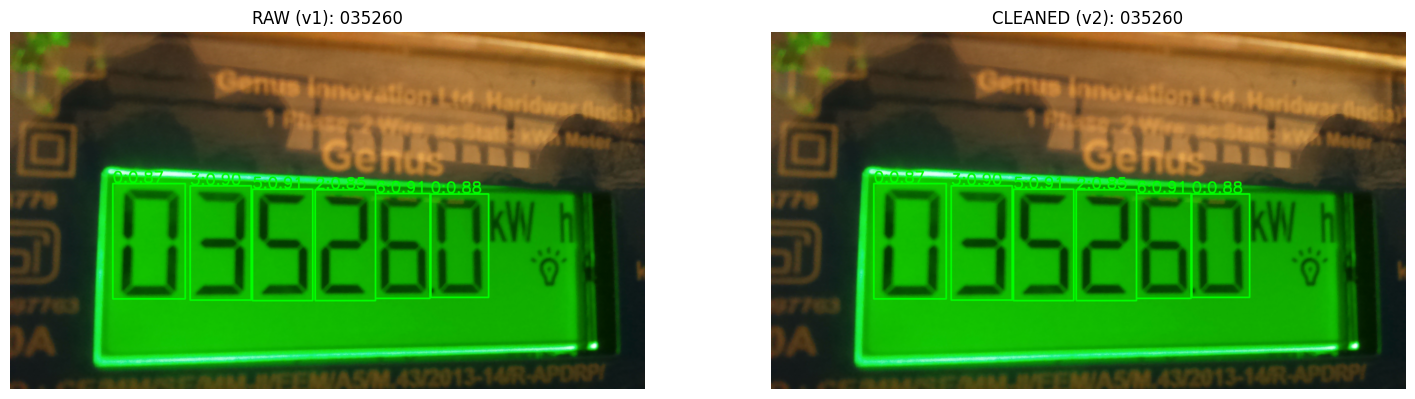

In [11]:
DIAG_IMAGE = test_images[0]      # <- change to any image path

def diagnose(image_path, low_conf=0.1):
    dets = sort_left_to_right(raw_predict(image_path, conf=low_conf), tilt_aware=False)
    print("Ground truth :", load_gt_string(image_path))
    print(f"\n{'#':>2} {'digit':>5} {'score':>6}   {'IoU w/ prev':>11} {'IoMin w/ prev':>13}")
    for i, d in enumerate(dets):
        if i == 0:
            io = im = 0.0
        else:
            io = iou_xyxy(d["box"], dets[i - 1]["box"])
            im = overlap_min(d["box"], dets[i - 1]["box"])
        flag = "  <-- OVERLAP" if (io >= 0.3 or im >= 0.5) else ""
        print(f"{i:>2} {d['digit']:>5} {d['score']:>6.3f}   {io:>11.2f} {im:>13.2f}{flag}")

    before, _ = decode(dets, conf=0.25, suppress_overlap=False, tilt_aware=False)
    after, kept = decode(dets, **DECODER)
    print("\nv1 behaviour (conf 0.25, no cleaning):", before)
    print("v2 behaviour (cleaned decoder)        :", after)

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    draw_dets(image_path, [d for d in dets if d["score"] >= 0.25], f"RAW (v1): {before}", axes[0])
    draw_dets(image_path, kept, f"CLEANED (v2): {after}", axes[1])
    plt.show()

diagnose(DIAG_IMAGE)

## Module 11 — Exact-match accuracy, baseline vs. fixed decoder

This is the metric that matters: **the percentage of images where the full predicted string equals the ground truth.**

Steps:
1. Run the network once per val/test image and cache the raw boxes.
2. Evaluate the **v1 decoder** (conf 0.25, no cleaning, plain x-sort) vs the **v2 decoder**.
3. **Sweep the confidence threshold on the validation set** and pick the best value (ties -> closest to 0.3).
4. Report the final numbers on the **test set**, which was never used for tuning.

In [12]:
def cache_split(split):
    paths = sorted((DATASET_DIR / "images" / split).glob("*"))
    return {p: raw_predict(p) for p in paths}

RAW_VAL, RAW_TEST = cache_split("val"), cache_split("test")
GT_VAL = {p: load_gt_string(p) for p in RAW_VAL}
GT_TEST = {p: load_gt_string(p) for p in RAW_TEST}

def exact_match(raw_cache, gt, **cfg):
    ok, errors = 0, []
    for p, dets in raw_cache.items():
        pred, _ = decode(dets, **cfg)
        if pred == gt[p]:
            ok += 1
        else:
            errors.append((p, gt[p], pred))
    return ok / max(1, len(raw_cache)), errors

V1_CFG = dict(conf=0.25, suppress_overlap=False, tilt_aware=False)

# ---- tune the confidence threshold on VALIDATION only ----
sweep = []
for conf in np.round(np.arange(0.10, 0.651, 0.05), 2):
    acc, _ = exact_match(RAW_VAL, GT_VAL, **{**DECODER, "conf": float(conf)})
    sweep.append((float(conf), acc))
best_conf = max(sweep, key=lambda s: (s[1], -abs(s[0] - 0.3)))[0]
DECODER["conf"] = best_conf

print("Validation exact-match vs confidence threshold:")
for c, a in sweep:
    print(f"  conf {c:.2f}: {a:.1%}" + ("   <-- chosen" if c == best_conf else ""))

# ---- final comparison ----
print("\n==================== EXACT-MATCH ACCURACY ====================")
for name, raw, gt in [("VAL ", RAW_VAL, GT_VAL), ("TEST", RAW_TEST, GT_TEST)]:
    a1, _ = exact_match(raw, gt, **V1_CFG)
    a2, _ = exact_match(raw, gt, **DECODER)
    print(f"{name}: v1 decoder {a1:.1%}   ->   v2 decoder {a2:.1%}   (conf={DECODER['conf']})")

Validation exact-match vs confidence threshold:
  conf 0.10: 96.0%
  conf 0.15: 96.0%
  conf 0.20: 96.0%
  conf 0.25: 96.0%
  conf 0.30: 96.0%   <-- chosen
  conf 0.35: 96.0%
  conf 0.40: 96.0%
  conf 0.45: 96.0%
  conf 0.50: 96.0%
  conf 0.55: 96.0%
  conf 0.60: 96.0%
  conf 0.65: 96.0%

==================== EXACT-MATCH ACCURACY ====================
VAL : v1 decoder 96.0%   ->   v2 decoder 96.0%   (conf=0.3)
TEST: v1 decoder 100.0%   ->   v2 decoder 100.0%   (conf=0.3)


## Module 12 — Error analysis

Classifies every remaining test error as an **extra digit**, a **missing digit**, or a **substitution**, and counts which digit pairs get confused. This tells you what to do next:

* mostly *extra* -> raise `conf` / tighten `iou_thresh`;
* mostly *missing* -> lower `conf`, use higher resolution or a larger model;
* mostly *substitutions* (e.g. 2<->5, 1<->7) -> more data for those digits, larger model, more epochs.

In [13]:
acc, errors = exact_match(RAW_TEST, GT_TEST, **DECODER)
print(f"Test exact-match: {acc:.1%}  ({len(RAW_TEST) - len(errors)}/{len(RAW_TEST)})\n")

extra, missing_d, subs = Counter(), Counter(), Counter()
for p, gt, pred in errors:
    print(f"{p.name[-30:]:>30}   GT={gt}   PRED={pred}")
    sm = difflib.SequenceMatcher(None, gt, pred)
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag == "replace":
            for a, b in zip(gt[i1:i2], pred[j1:j2]):
                subs[(a, b)] += 1
            if (i2 - i1) > (j2 - j1):
                missing_d.update(gt[i1 + (j2 - j1):i2])
            elif (j2 - j1) > (i2 - i1):
                extra.update(pred[j1 + (i2 - i1):j2])
        elif tag == "delete":
            missing_d.update(gt[i1:i2])
        elif tag == "insert":
            extra.update(pred[j1:j2])

print("\nExtra digits predicted  :", dict(extra))
print("Missing digits          :", dict(missing_d))
print("Substitutions (GT->PRED):", {f"{a}->{b}": n for (a, b), n in subs.most_common()})

# show up to 4 failing images
bad = errors[:4]
if bad:
    fig, axes = plt.subplots(1, len(bad), figsize=(6 * len(bad), 5), squeeze=False)
    for ax, (p, gt, pred) in zip(axes[0], bad):
        _, kept = decode(RAW_TEST[p], **DECODER)
        draw_dets(p, kept, f"GT {gt} | PRED {pred}", ax)
    plt.show()

Test exact-match: 100.0%  (26/26)


Extra digits predicted  : {}
Missing digits          : {}
Substitutions (GT->PRED): {}


## Module 13 — Read a new meter photo

Upload any meter image. The cleaned decoder with the tuned confidence is used.

Saving 1.JPG to 1.JPG


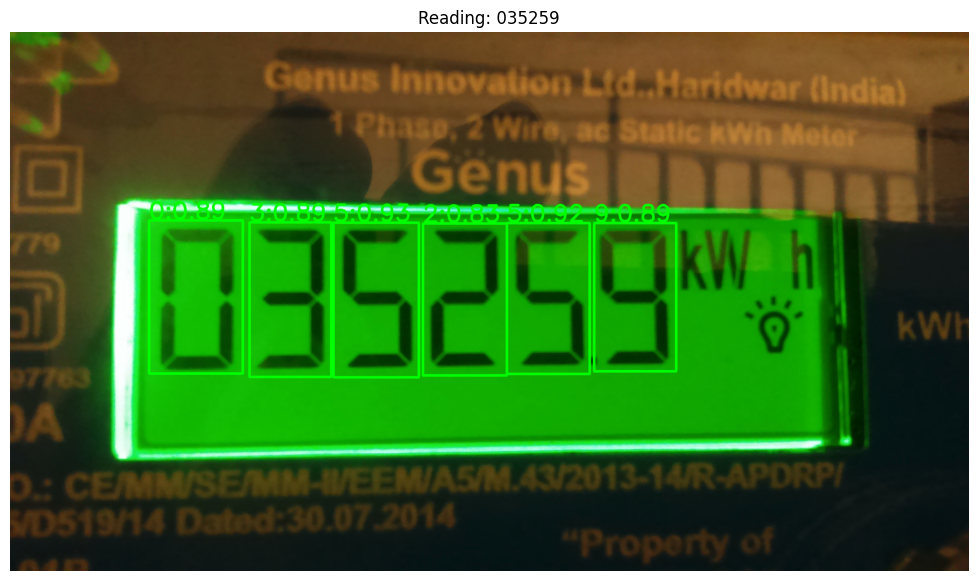

METER READING: 035259
Digit confidences: [('0', 0.89), ('3', 0.89), ('5', 0.93), ('2', 0.83), ('5', 0.92), ('9', 0.89)]


In [15]:
new_files = files.upload()
new_image = next(iter(new_files.keys()))
reading, kept = read_meter(new_image, show=True)
print("METER READING:", reading)
print("Digit confidences:", [(d["digit"], round(d["score"], 2)) for d in kept])
low = [d["digit"] for d in kept if d["score"] < 0.5]
if low:
    print("Low-confidence digits (double-check manually):", low)

## Module 14 — Save and download the model and decoder settings

In [16]:
EXPORT_DIR = Path("/content/meter_yolo_export_v2")
EXPORT_DIR.mkdir(exist_ok=True)
shutil.copy2(BEST_MODEL, EXPORT_DIR / "best.pt")
shutil.copy2(yaml_path, EXPORT_DIR / "meter_digits.yaml")
with open(EXPORT_DIR / "digit_classes.json", "w") as f:
    json.dump({str(k): v for k, v in yolo_names.items()}, f, indent=2)
with open(EXPORT_DIR / "decoder_config.json", "w") as f:
    json.dump({"imgsz": IMAGE_SIZE, "raw_conf": 0.05, "raw_nms_iou": 0.7, **DECODER}, f, indent=2)

shutil.make_archive("/content/meter_yolo_export_v2", "zip", EXPORT_DIR)
files.download("/content/meter_yolo_export_v2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes and remaining limitations

* **Why the extra `5` appeared:** the detector produced a second box near the true `5`/`2` digits. The most likely causes are a duplicate box or a 2<->5 confusion made worse by horizontal-flip augmentation. Overlap suppression removes duplicates; `fliplr=0` plus a larger model addresses the confusion. Modules 10 and 12 tell you which one applies to your data.
* **Overlap suppression keeps the *more confident* box.** If the wrong class has the higher score you will get a substitution instead of an extra digit; only better training fixes that.
* **Do not force `expected_digits`** unless every meter has the same number of digits (this dataset averages about 5.8 labelled digits per image, so lengths vary).
* **Decimal points / units** are not modelled. Add a `decimal` class and update the decoder if your readings need it.
* **Tilt-aware ordering** assumes a single text line within about 45 degrees of horizontal. Multi-row displays need a row-grouping step.
* **Small dataset (168 images):** keep an eye on leakage (random image-level split) and collect more night / blurred / tilted examples if accuracy is lower in those conditions.